# LinkAja Syariah 2027 to 2032: Monte Carlo Simulation of the Nava Solution

**Our recommendation:** *Nava by LinkAja*, #TheOnlyMuslimAppYouNeed. Three pillars: (1) the Nava app, (2) awareness and activation through KOLs, mosque QRIS, and festivals, and (3) loyalty through Quest, Widget, and Muhasabah.

This notebook tests the feasibility of the solution with a 10,000-run Monte Carlo simulation. All code is here, in order, and runs from top to bottom without any other file.

| Part | Question it answers |
|---|---|
| **0** | How does the simulation work, in plain words? |
| **1** | What happens if LinkAja Syariah does nothing (baseline)? |
| **2** | How much does MAU rise with the Nava solution compared with the baseline? |
| **3** | Which pillar does the work, and which assumptions matter most? |
| **4** | What is the yearly growth, and how much cost is still worth it (break-even)? |
| **5** | What is the probability that the solution succeeds, with and without mitigation of execution risk? |

> Every number is the output of a model built on the assumptions written in this notebook. It is not a certain prediction and not an official LinkAja figure. The most defensible numbers are the percentage uplifts, not the absolute MAU levels, because Syariah MAU is not published.

## 0. How the simulation works (plain words)

For each of 10,000 "possible worlds" from 2027 to 2032:

1. **Do-nothing world.** Registered users and monthly active users (MAU) keep growing at a pace that keeps slowing down (an S-curve, Bass 1969). On top of that sit random elements: the economy, a possible recession, sudden shocks (for example a service disruption or a competitor move), Ramadan seasonality, and monthly noise.
2. **Solution world.** The **exact same** random world, with the three pillars added:
   - **Pillar 1 (Nava app)** raises the ratio of active users to registered users.
   - **Pillar 2 (activation)** adds new registered users, some of whom become active.
   - **Pillar 3 (loyalty)** raises retention: one step up in level, then a small compounding gain every year.
   - The size of each effect is drawn from a range (minimum, most likely, maximum). Effects build up gradually, not instantly, and they overlap. The active ratio is capped near 12.5% (the Muslim Pro ratio).
3. **Compare within the same world.** The difference between the solution world and the do-nothing world comes from the solution, not from luck (common random numbers).
4. **Execution risk.** A pillar can fail completely. Part 5 computes the probability of success when that is possible, with and without a mitigation design.

## 0.1 Setup

In [1]:
import os, itertools
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110})

OUT = "output_notebook"          # charts are also saved here as PNG files
os.makedirs(OUT, exist_ok=True)

def show(df, digits=2):
    display(df.style.hide(axis="index").format(precision=digits))

### Public data used as anchors

LinkAja Syariah registered users: 1.6 million (end of 2020), 5.8 million (Nov 2021), 7.5 million (Jul 2022), more than 9 million (Aug 2026), and about 10 million (Nov 2026). Growth has already slowed to about 4.5% to 6.9% per year since 2022. This fast-then-flattening pattern matches an S-curve (Bass, 1969). Syariah MAU is not published, so its starting level is modelled as a distribution, not a single number.

## 0.2 Baseline engine (the do-nothing world)

Baseline parameters are ranges (triangular or uniform), and one set of parameters is drawn per world. The code below defines the parameters, the randomness (a heavy-tailed AR(1) macro factor, recession, Poisson shocks, Ramadan seasonality), and the `simulate` function.

In [2]:
START_YEAR = 2027
N_YEARS = 6
N_MONTHS = N_YEARS * 12
MAU_CAP_RATIO = 0.35

# (name, distribution, arguments)  tri = triangular(min, mode, max), uni = uniform(min, max)
PARAMS = [
    ("R0", "tri", (9.5, 10.0, 10.8)),         # initial registered users (million)
    ("a0", "tri", (0.05, 0.08, 0.125)),       # initial MAU / registered ratio
    ("g1", "tri", (0.03, 0.055, 0.08)),       # registered-user growth, year 1
    ("g_inf", "tri", (0.005, 0.015, 0.025)),  # registered-user growth, long run
    ("lam_g", "uni", (0.2, 0.6)),             # decay of registered-user growth
    ("h1", "tri", (0.03, 0.08, 0.15)),        # MAU growth, year 1
    ("h_inf", "tri", (0.0, 0.02, 0.04)),      # MAU growth, long run
    ("mu_h", "uni", (0.2, 0.7)),              # decay of MAU growth
    ("kappa", "tri", (-0.10, 0.0, 0.25)),     # change in competitive pressure
    ("beta", "tri", (0.0, 1.0, 3.0)),         # MAU sensitivity to consumption
    ("A", "tri", (0.02, 0.06, 0.12)),         # Ramadan amplitude
    ("shock_rate", "tri", (0.1, 0.3, 0.6)),   # special events per year
    ("sigma_idio", "tri", (0.005, 0.01, 0.02)),  # monthly MAU noise
]

MACRO_SIGMA = 0.003
MACRO_RHO = 0.5
MACRO_T_DF = 5
RECESSION_PROB = 0.03
RECESSION_DROP = (0.02, 0.04)
SHOCK_SIZE = (0.02, 0.10)
SHOCK_RECOVERY = 1.0 / 12.0
NOISE_PHI = 0.7
ADDS_NOISE_SIGMA = 0.20

RAMADAN_STARTS = ["2027-02-08", "2028-01-28", "2029-01-16", "2030-01-05",
                  "2030-12-26", "2031-12-15", "2032-12-04"]

NAVY, GOLD, GOLD_DARK = "#1f3b73", "#e6b422", "#b7791f"

In [3]:
def ramadan_weights():
    days = set()
    for s in RAMADAN_STARTS:
        d0 = dt.date.fromisoformat(s)
        days.update(d0 + dt.timedelta(days=i) for i in range(30))
    w = []
    for m in range(N_MONTHS):
        y, mo = START_YEAR + m // 12, m % 12 + 1
        first = dt.date(y, mo, 1)
        nxt = dt.date(y + (mo == 12), mo % 12 + 1, 1)
        nd = (nxt - first).days
        w.append(sum(first + dt.timedelta(days=i) in days for i in range(nd)) / nd)
    return np.array(w)


def draw_parameters(rng, n):
    cols = {}
    for name, dist, args in PARAMS:
        cols[name] = rng.triangular(*args, size=n) if dist == "tri" else rng.uniform(*args, size=n)
    return pd.DataFrame(cols)


def simulate(rng, n):
    p = draw_parameters(rng, n)
    rw = ramadan_weights()

    # yearly deviation of consumption growth: AR(1), Student t, rare recession
    scale_t = np.sqrt(MACRO_T_DF / (MACRO_T_DF - 2))
    dev = np.zeros((n, N_YEARS))
    prev = np.zeros(n)
    for k in range(N_YEARS):
        innov = MACRO_SIGMA * rng.standard_t(MACRO_T_DF, size=n) / scale_t
        rec = rng.random(n) < RECESSION_PROB
        innov = innov - rec * rng.uniform(*RECESSION_DROP, size=n)
        prev = MACRO_RHO * prev + innov
        dev[:, k] = prev
    macro_effect = p["beta"].values[:, None] * dev

    R = p["R0"].values * 1e6
    trend = R * p["a0"].values
    sf = np.ones(n)
    eta = np.zeros(n)
    n_events = np.zeros(n)
    R_path = np.zeros((n, N_MONTHS))
    MAU_path = np.zeros((n, N_MONTHS))
    MAU_sa = np.zeros((n, N_MONTHS))  # MAU without the Ramadan uplift

    for m in range(N_MONTHS):
        k = m // 12

        # registered users
        g_k = p["g_inf"] + (p["g1"] - p["g_inf"]) * np.exp(-p["lam_g"] * k)
        r_m = (1.0 + g_k.values * (1.0 - p["kappa"].values)) ** (1.0 / 12.0) - 1.0
        R = R * (1.0 + r_m * rng.lognormal(-0.5 * ADDS_NOISE_SIGMA ** 2, ADDS_NOISE_SIGMA, size=n))

        # MAU trend
        h_k = p["h_inf"] + (p["h1"] - p["h_inf"]) * np.exp(-p["mu_h"] * k)
        h_eff = h_k.values * (1.0 - p["kappa"].values) + macro_effect[:, k]
        trend = trend * ((1.0 + h_eff) ** (1.0 / 12.0))

        # special events: cut, then recover
        sf = sf + (1.0 - sf) * SHOCK_RECOVERY
        ev = rng.random(n) < (1.0 - np.exp(-p["shock_rate"].values / 12.0))
        sf = np.where(ev, sf * (1.0 - rng.uniform(*SHOCK_SIZE, size=n)), sf)
        n_events += ev

        # monthly noise and Ramadan seasonality
        eta = NOISE_PHI * eta + p["sigma_idio"].values * rng.standard_normal(n)
        season = 1.0 + p["A"].values * rw[m]
        R_path[:, m] = R
        MAU_path[:, m] = np.minimum(trend * sf * season * np.exp(eta), MAU_CAP_RATIO * R)
        MAU_sa[:, m] = np.minimum(trend * sf * np.exp(eta), MAU_CAP_RATIO * R)

    drivers = p.copy()
    drivers["macro_effect"] = macro_effect.sum(axis=1)
    drivers["n_events"] = n_events
    return {"R": R_path, "MAU": MAU_path, "MAU_sa": MAU_sa, "drivers": drivers,
            "MAU0": p["R0"].values * 1e6 * p["a0"].values}


def yearly(arr):
    a = arr.reshape(arr.shape[0], N_YEARS, 12)
    return a.mean(axis=2), a[:, :, -1]

Helper functions for baseline tables and charts:

In [4]:
def pct_table(avg, scale=1e6):
    rows = []
    for k in range(N_YEARS):
        rows.append({"Year": START_YEAR + k,
                     "P5 (lower bound)": np.percentile(avg[:, k], 5) / scale,
                     "P50 (baseline)": np.percentile(avg[:, k], 50) / scale,
                     "P95 (upper bound)": np.percentile(avg[:, k], 95) / scale})
    return pd.DataFrame(rows)


def tail_table(drivers, target):
    p_lo, p_hi = np.percentile(target, [5, 95])
    bear, bull = drivers[target <= p_lo], drivers[target >= p_hi]
    labels = {"h1": "MAU growth, year 1", "h_inf": "MAU growth, long run",
              "mu_h": "Decay speed of MAU growth", "kappa": "Change in competitive pressure",
              "n_events": "Number of special events (6 years)", "macro_effect": "Cumulative macro effect",
              "beta": "MAU sensitivity to consumption", "A": "Ramadan amplitude"}
    rows = []
    for c, lb in labels.items():
        rows.append({"Factor": lb, "Bearish (<=P5)": bear[c].mean(),
                     "All simulations": drivers[c].mean(), "Bullish (>=P95)": bull[c].mean()})
    return pd.DataFrame(rows)


def month_axis():
    return pd.date_range(f"{START_YEAR}-01-01", periods=N_MONTHS, freq="MS")


def clean(ax):
    ax.grid(alpha=0.25)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)


def chart_fan(mau_full, mau_trend, end_vals, fname, scale=1e6):
    x = month_axis()
    p5, p95 = [np.percentile(mau_full, q, axis=0) / scale for q in (5, 95)]
    p50_full = np.percentile(mau_full, 50, axis=0) / scale
    p50_trend = np.percentile(mau_trend, 50, axis=0) / scale
    fig, ax = plt.subplots(figsize=(11, 5.8))
    for i, s in enumerate(RAMADAN_STARTS):
        d0 = pd.Timestamp(s)
        ax.axvspan(d0, d0 + pd.Timedelta(days=30), color=GOLD, alpha=0.22, linewidth=0,
                   label="Ramadan month" if i == 0 else None)
    ax.fill_between(x, p5, p95, color=NAVY, alpha=0.12, linewidth=0, label="P5 to P95 range")
    ax.plot(x, p95, color=NAVY, lw=0.9, ls="--", alpha=0.5)
    ax.plot(x, p5, color=NAVY, lw=0.9, ls="--", alpha=0.5)
    ax.plot(x, p50_full, color=GOLD_DARK, lw=1.3, label="P50 with Ramadan uplift")
    ax.plot(x, p50_trend, color=NAVY, lw=2.8, label="P50 trend line (baseline)")
    for v, y, nm in ((end_vals[2], p95[-1], "P95"), (end_vals[1], p50_trend[-1], "P50"),
                     (end_vals[0], p5[-1], "P5")):
        ax.annotate(f"{nm} (2032 average): {v:.2f}", (x[-1], y), xytext=(8, 0),
                    textcoords="offset points", va="center", fontsize=9, color=NAVY)
    ax.set_xlim(x[0], x[-1] + pd.Timedelta(days=330))
    ax.set_title("Baseline MAU Projection, LinkAja Syariah 2027 to 2032 (10,000 simulations)",
                 fontsize=12.5, fontweight="bold")
    ax.set_ylabel("MAU (million)")
    clean(ax)
    ax.legend(loc="upper left", frameon=False, fontsize=9)
    fig.tight_layout()
    fig.savefig(fname, dpi=170)
    plt.show()


def chart_spaghetti(mau_trend, fname, k=120, scale=1e6):
    x = month_axis()
    idx = np.random.default_rng(7).choice(mau_trend.shape[0], size=k, replace=False)
    fig, ax = plt.subplots(figsize=(10.5, 5.6))
    for i in idx:
        ax.plot(x, mau_trend[i] / scale, color="#6f8fc7", lw=0.6, alpha=0.28)
    for q, ls, lw, lb in ((95, "--", 1.4, "P95"), (5, "--", 1.4, "P5"), (50, "-", 2.8, "P50 (baseline)")):
        ax.plot(x, np.percentile(mau_trend, q, axis=0) / scale, color=NAVY, ls=ls, lw=lw, label=lb)
    ax.set_title(f"{k} Random Simulation Paths out of 10,000 (without Ramadan seasonality)",
                 fontsize=12.5, fontweight="bold")
    ax.set_ylabel("MAU (million)")
    clean(ax)
    ax.legend(loc="upper left", frameon=False)
    fig.tight_layout()
    fig.savefig(fname, dpi=170)
    plt.show()


def chart_hist(target, fname, scale=1e6):
    t = target / scale
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    ax.hist(t, bins=60, color="#8fb0de", edgecolor="white")
    for v, c, lb in zip(np.percentile(t, [5, 50, 95]), ("#b03a2e", NAVY, "#1e8449"), ("P5", "P50", "P95")):
        ax.axvline(v, color=c, lw=2, label=f"{lb}: {v:.2f} million")
    ax.set_title("Distribution of 2032 Average MAU (baseline, 10,000 simulations)", fontsize=12, fontweight="bold")
    ax.set_xlabel("MAU (million)")
    ax.set_ylabel("number of simulations")
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(fname, dpi=160)
    plt.show()

## 0.3 Solution engine (three pillars)

The effect size of each pillar is a **team assumption**: there is no conversion data for KOLs, mosque QRIS, or retention at LinkAja. So every effect is written as a range (minimum / most likely / maximum), and Parts 3 and 4 test how sensitive the result is.

In [5]:
LO, HI = 10, 90         # reported lower and upper bounds (percentiles)
RATIO_CAP = 0.125       # cap on the active/registered ratio: Muslim Pro (5 million active out of 40 million registered)
EFFECT_SEED = 99          # separate random stream for solution effects; the baseline is unchanged
RISK_SEED = 777         # separate random stream for execution failure
F_GRID = (0.0, 0.1, 0.2, 0.3, 0.4)   # probability that each pillar fails completely (assumption, shown as a range)
F_MAIN = 0.3           # cautious value used as the headline figure
MIT_C = 0.10            # mitigation: probability that all channels/features of a pillar fail from a common cause
MIT_Q2 = 0.5            # mitigation: probability that the relaunch also fails, given that the first launch failed
MIT_DELAY = 9           # mitigation: months of delay in effects if the app has to be relaunched
CONFIDENCE = 0.8         # confidence level for the target that can be promised
BASE_USERS_2032 = 92e6 * 1.015 ** 6    # total LinkAja base in 2032: 92 million growing 1.5% per year

# effect of each pillar (min, mode, max) and time for the effect to build up (months); one parameter set per simulation
#   m1 : multiplier on the active ratio from the Nava app (pillar 1)
#   u1 : extra registered users from the Nava app (pillar 1)
#   u2 : extra registered users from KOL, mosque, and festival activation (pillar 2)
#   q  : activity of new users relative to the average (pillar 2)
#   m3 : MAU multiplier from retention (pillar 3)
#   om : overlap factor between pillars
#   t1, t2, t3 : time for the effect of pillar 1, 2, 3 to build up
EFFECTS = dict(m1=(1.05, 1.20, 1.45), u2=(0.03, 0.09, 0.20), u1=(0, 0, 0), q=(0.5, 0.8, 1.0),
            m3=(1.02, 1.08, 1.18), om=(0.7, 1.0), t1=(8, 18), t2=(6, 15), t3=(12, 24),
            g3=(0.0, 0.01, 0.025))   # g3: extra MAU growth per year from pillar 3 retention (ASSUMPTION, no data yet)
PILLARS = {"Pillar 1 (Nava app)": (True, False, False), "Pillar 2 (activation)": (False, True, False),
         "Pillar 3 (loyalty)": (False, False, True)}
COLORS = {"Baseline": "#1f3b73", "Solution": "#1e8449"}

# public data on LinkAja Syariah registered users (million); x value = year number, December position of that year
HIST_REGISTERED = [(2020.0, 1.6, "Dec 2020"), (2021 - 1 / 12, 5.8, "Nov 2021"), (2022 - 5 / 12, 7.5, "Jul 2022"),
                  (2026 - 4 / 12, 9.0, "Aug 2026"), (2026 - 1 / 12, 10.0, "Nov 2026")]

Effect formulas (time `t` in months, `tau` is the time for the effect to build up):

```
Ramp of pillar i:            r_i(t) = 1 - exp(-t / tau_i)
Registered users, solution:  R'(t)  = R(t) * (1 + U2*r_2(t) + U1*r_1(t))
Pillar 1 factor:             f1(t)  = 1 + (M1 - 1)*r_1(t)
New-user factor:             f2(t)  = 1 + q*(U2*r_2(t) + U1*r_1(t))
Pillar 3 factor:             f3(t)  = (1 + (M3 - 1)*r_3(t)) * (1 + G3)^( r_3(t)*t/12 )     (compounding retention)
MAU uplift:                  L(t)   = omega * ( f1*f2*f3 - 1 )         (omega = 1 if only one pillar runs)
MAU with solution:           MAU'(t) = min( MAU(t)*(1 + L(t)),  max_ratio * R'(t) )
```

In [6]:
def tri(rng, a, n):
    if a[0] == a[2]:
        return np.full((n, 1), float(a[1]))
    return rng.triangular(*a, size=(n, 1))


def draw_effects(n, s):
    rng = np.random.default_rng(EFFECT_SEED)
    p = {k: tri(rng, s[k], n) for k in ("m1", "u2", "u1", "q", "m3")}
    p["om"] = rng.uniform(*s["om"], size=(n, 1))
    for k in ("t1", "t2", "t3"):
        p[k] = rng.uniform(*s[k], size=(n, 1))
    p["g3"] = tri(rng, s["g3"], n)    # drawn last so that the draws of the other parameters do not change
    return p


def compute_effects(p, pillars=(True, True, True), delay=0):
    # relative MAU uplift (up) and relative registered-user uplift (reg_up), per month
    # delay: months of delay in the effects of pillars 1 and 3 (app relaunched)
    t = np.arange(1, N_MONTHS + 1)[None, :]
    tl = np.clip(t - delay, 0, None)
    r1, r3 = [1 - np.exp(-tl / p[k]) for k in ("t1", "t3")]
    r2 = 1 - np.exp(-t / p["t2"])
    p1, p2, p3 = pillars
    reg_up = np.zeros_like(r1)
    if p2:
        reg_up = reg_up + p["u2"] * r2
    if p1:
        reg_up = reg_up + p["u1"] * r1
    f1 = 1 + (p["m1"] - 1) * r1 if p1 else 1.0
    # pillar 3: level uplift (m3) plus compounding retention: extra growth g3 per year since the effect started
    f3 = (1 + (p["m3"] - 1) * r3) * (1 + p["g3"]) ** (r3 * tl / 12) if p3 else 1.0
    up = f1 * (1 + p["q"] * reg_up) * f3 - 1
    if sum(pillars) > 1:
        up = up * p["om"]
    return up, reg_up


def apply_effects(mau, R, up, reg_up):
    # the active ratio is capped at 12.5% (or at the baseline ratio if that is already higher)
    reg_s = R * (1 + reg_up)
    cap = np.minimum(np.maximum(RATIO_CAP, mau / R), MAU_CAP_RATIO)
    return np.minimum(mau * (1 + up), cap * reg_s), reg_s


def run_solution(res, n):
    p = draw_effects(n, EFFECTS)
    up, reg_up = compute_effects(p)
    mau_s, reg_s = apply_effects(res["MAU"], res["R"], up, reg_up)
    mau_sa, _ = apply_effects(res["MAU_sa"], res["R"], up, reg_up)
    out = dict(p=p, mau=mau_s, mau_sa=mau_sa, reg=reg_s, up=up, reg_up=reg_up)
    for pn, flags in PILLARS.items():
        u1, r1 = compute_effects(p, flags)
        out[pn], _ = apply_effects(res["MAU"], res["R"], u1, r1)
    return out

Helper functions for the solution: tables, and the regression used for the history before 2027.

In [7]:
def pc(x, axis=None):
    return np.percentile(x, [LO, 50, HI], axis=axis)


def historical_regression():
    # saturating exponential regression R(t) = K - c exp(-b (t - 2020)) on the public data points
    x = np.array([h[0] for h in HIST_REGISTERED]); y = np.array([h[1] for h in HIST_REGISTERED])
    best = None
    for b in np.linspace(0.05, 3, 600):
        A = np.c_[np.ones_like(x), -np.exp(-b * (x - 2020))]
        coef = np.linalg.lstsq(A, y, rcond=None)[0]
        sse = ((A @ coef - y) ** 2).sum()
        if best is None or sse < best[0]:
            best = (sse, b, coef)
    sse, b, (K, c) = best
    r2 = 1 - sse / ((y - y.mean()) ** 2).sum()
    return (lambda t: K - c * np.exp(-b * (np.asarray(t) - 2020))), r2

In [8]:
def table_main(res, sol):
    # yearly average MAU (million)
    yb, _ = yearly(res["MAU"]); ys, _ = yearly(sol["mau"])
    rows = []
    for k in range(N_YEARS):
        r = {"Year": START_YEAR + k}
        r["Do nothing P10"], r["Do nothing P50"], r["Do nothing P90"] = pc(yb[:, k] / 1e6)
        r["Solution P10"], r["Solution P50"], r["Solution P90"] = pc(ys[:, k] / 1e6)
        rows.append(r)
    return pd.DataFrame(rows)


def table_index(res, sol):
    # indexed MAU (Dec 2026 = 100, per simulation) and the "solution worst case vs do nothing best case" test
    yb, _ = yearly(res["MAU_sa"]); ys, _ = yearly(sol["mau_sa"])
    m0 = res["MAU0"][:, None]
    ib, is_ = pc(yb / m0 * 100, axis=0), pc(ys / m0 * 100, axis=0)
    rows = []
    for k in range(N_YEARS):
        rows.append({"Year": START_YEAR + k, "Do nothing P10": ib[0, k], "Do nothing P50": ib[1, k],
                     "Do nothing P90": ib[2, k], "Solution P10": is_[0, k], "Solution P50": is_[1, k], "Solution P90": is_[2, k],
                     "Solution P10 above do nothing P90": bool(is_[0, k] > ib[2, k]),
                     "Solution wins in the same simulation (%)": np.mean(ys[:, k] > yb[:, k]) * 100})
    return pd.DataFrame(rows)


def table_uplift_by_year(res, sol):
    yb, _ = yearly(res["MAU"]); ys, _ = yearly(sol["mau"])
    rows = []
    for k in range(N_YEARS):
        r = {"Year": START_YEAR + k}
        r["Uplift P10 (%)"], r["Uplift P50 (%)"], r["Uplift P90 (%)"] = pc((ys[:, k] / yb[:, k] - 1) * 100)
        rows.append(r)
    return pd.DataFrame(rows)


def table_summary(res, sol):
    yb, _ = yearly(res["MAU"]); ys, _ = yearly(sol["mau"])
    _, rb = yearly(res["R"]); _, rs = yearly(sol["reg"])
    mau0 = res["MAU0"]
    u = pc((ys[:, -1] / yb[:, -1] - 1) * 100)
    ratio = sol["mau"][:, -1] / sol["reg"][:, -1]
    cap_active = np.mean(ratio >= RATIO_CAP - 1e-9) * 100
    rows = [
        ("MAU uplift 2032 P10 (%)", u[0]), ("MAU uplift 2032 P50 (%)", u[1]), ("MAU uplift 2032 P90 (%)", u[2]),
        ("MAU 2032 do nothing, P50 (million)", np.median(yb[:, -1]) / 1e6),
        ("MAU 2032 with solution, P50 (million)", np.median(ys[:, -1]) / 1e6),
        ("Extra MAU 2032, paired median (million)", np.median(ys[:, -1] - yb[:, -1]) / 1e6),
        ("MAU growth per year, do nothing, P50 (%)", (np.median(yb[:, -1] / mau0) ** (1 / 5.5) - 1) * 100),
        ("MAU growth per year, with solution, P50 (%)", (np.median(ys[:, -1] / mau0) ** (1 / 5.5) - 1) * 100),
        ("MAU growth in year 1, with solution, P50 (%)", np.median(ys[:, 0] / mau0 - 1) * 100),
        ("Registered-user uplift 2032, P50 (%)", np.median(rs[:, -1] / rb[:, -1] - 1) * 100),
        ("Extra registered users 2032 (million)", np.median(rs[:, -1] - rb[:, -1]) / 1e6),
        ("Share of the LinkAja base 2032, with solution (%)", np.median(rs[:, -1]) / BASE_USERS_2032 * 100),
        ("Active ratio 2032, do nothing, P50 (%)", np.median(res["MAU"][:, -1] / res["R"][:, -1]) * 100),
        ("Active ratio 2032, with solution, P50 (%)", np.median(ratio) * 100),
        ("Simulations hitting the 12.5% active-ratio cap (%)", cap_active),
        ("Solution above do nothing in the same simulation (%)", np.mean(ys[:, -1] > yb[:, -1]) * 100),
        ("Probability that solution MAU exceeds do nothing P90 (%)", np.mean(ys[:, -1] > np.percentile(yb[:, -1], HI)) * 100),
    ]
    return pd.DataFrame(rows, columns=["Measure", "Value"])


def table_pillars(res, sol):
    yb, _ = yearly(res["MAU"])
    rows = []
    for pn in list(PILLARS) + ["Combined (after overlap)"]:
        arr = sol["mau"] if pn.startswith("Combined") else sol[pn]
        q = pc((yearly(arr)[0][:, -1] / yb[:, -1] - 1) * 100)
        rows.append({"Pillar": pn, "MAU uplift 2032 P50 (%)": q[1], "P10 (%)": q[0], "P90 (%)": q[2]})
    return pd.DataFrame(rows)


def table_assumptions():
    name = {"m1": "Pillar 1: active-ratio multiplier (Nava app)", "u1": "Pillar 1: extra registered users from the app",
            "u2": "Pillar 2: extra registered users (KOL, mosque, festival)", "q": "Pillar 2: activity of new users",
            "m3": "Pillar 3: MAU multiplier from retention", "om": "Overlap between pillars (multiplier on the combined effect)",
            "g3": "Pillar 3: extra MAU growth per year from retention (compounding)",
            "t1": "Build-up time of pillar 1 effect (months)", "t2": "Build-up time of pillar 2 effect (months)",
            "t3": "Build-up time of pillar 3 effect (months)"}
    return pd.DataFrame([(lb, ("uniform " if len(EFFECTS[k]) == 2 else "") + " / ".join(f"{v:g}" for v in EFFECTS[k]))
                         for k, lb in name.items()], columns=["Parameter", "Min / mode / max"])


def table_sensitivity(res, sol):
    yb, _ = yearly(res["MAU"]); ys, _ = yearly(sol["mau"])
    u = ys[:, -1] / yb[:, -1] - 1
    rows = []
    for k, v in sol["p"].items():
        if v.std() > 0:     # constant parameters (u1 = 0) are skipped
            rows.append((k, pd.Series(v[:, 0]).rank().corr(pd.Series(u).rank())))
    df = pd.DataFrame(rows, columns=["parameter", "spearman"])
    return df.reindex(df["spearman"].abs().sort_values(ascending=False).index).reset_index(drop=True)


def table_plausibility(res):
    # plausibility check of the baseline against the data anchors
    r0 = res["drivers"]["R0"].values * 1e6
    g_reg = res["R"][:, 11] / r0 - 1
    g_mau = res["MAU_sa"][:, 11] / res["MAU0"] - 1
    share = res["R"][:, -1] / BASE_USERS_2032
    rows = [
        ("Registered-user growth 2027 (%)", *(pc(g_reg) * 100), "history 2022 to 2026: 4.5 to 6.9 per year"),
        ("MAU trend growth 2027 (%)", *(pc(g_mau) * 100), "total LinkAja MAU +5% (2026); Syariah MAU +20% (2024)"),
        ("Share of the LinkAja base 2032 (%)", *(pc(share) * 100), "2022: 8.6; 2026: 10.9"),
    ]
    df = pd.DataFrame(rows, columns=["Measure", "P10", "P50", "P90", "Data anchor"])
    df.loc[len(df)] = ["Simulations with 2027 registered-user growth inside the historical range (%)",
                       np.nan, np.mean((g_reg >= 0.045) & (g_reg <= 0.069)) * 100, np.nan, "4.5 to 6.9 per year"]
    return df

Chart functions for the solution:

In [9]:
def save_fig(fig, fname, dpi=190):
    fig.savefig(fname, dpi=dpi, bbox_inches="tight")
    plt.show()

In [10]:
def chart_main(res, sol, fname):
    # one chart: do nothing vs solution, indexed MAU (Dec 2026 = 100), P10 to P90 band
    # history before 2027: regression on registered users, assuming a constant active ratio
    yrs = np.arange(2027, 2033)
    c_b, c_s = COLORS["Baseline"], COLORS["Solution"]
    f, r2 = historical_regression()
    base = float(f(2026.0))
    fig, ax = plt.subplots(figsize=(10.5, 5.8))

    tt = np.linspace(2020.0, 2026.0, 200)
    ax.plot(tt, f(tt) / base * 100, "-", color="#222831", lw=2.4, label="Historical (regression estimate)")
    ax.plot([h[0] for h in HIST_REGISTERED], [h[1] / base * 100 for h in HIST_REGISTERED], "o", color="#222831",
            ms=6.5, label="Public data on registered users")

    yb, _ = yearly(res["MAU_sa"]); ys, _ = yearly(sol["mau_sa"])
    m0 = res["MAU0"][:, None]
    pb, ps = pc(yb / m0 * 100, axis=0), pc(ys / m0 * 100, axis=0)
    xx = np.r_[2026, yrs]
    ax.plot(xx, np.r_[100, pb[1]], "--o", color=c_b, lw=2.6, ms=6, label="Do nothing")
    ax.plot(xx, np.r_[100, ps[1]], "-o", color=c_s, lw=2.8, ms=6, label="With the Nava solution")
    ax.fill_between(yrs, pb[0], pb[2], color=c_b, alpha=0.14, lw=0)
    ax.fill_between(yrs, ps[0], ps[2], color=c_s, alpha=0.16, lw=0)
    ax.text(2032.2, pb[1][-1], f"{pb[1][-1]:.0f}", color=c_b, fontsize=11, fontweight="bold", va="center")
    ax.text(2032.2, ps[1][-1], f"{ps[1][-1]:.0f}", color=c_s, fontsize=11, fontweight="bold", va="center")
    ax.annotate("", xy=(2032.75, ps[1][-1]), xytext=(2032.75, pb[1][-1]), arrowprops=dict(arrowstyle="<->", color="#333", lw=1.3))
    ax.text(2032.9, (ps[1][-1] + pb[1][-1]) / 2, f"+{(ps[1][-1] / pb[1][-1] - 1) * 100:.0f}%", fontsize=10.5,
            fontweight="bold", va="center")
    ax.axvline(2026, color="#888", lw=0.8, ls=":")
    cb, cs = [np.median(((yearly(m)[0][:, -1] / res["MAU0"]) ** (1 / EFFECTIVE_YEARS) - 1) * 100) for m in (res["MAU_sa"], sol["mau_sa"])]
    ax.text(2026.1, 190, f"Growth per year (Dec 2026 to 2032)\nDo nothing {cb:.1f}%   |   Nava {cs:.1f}%",
            fontsize=10, fontweight="bold", color="#222", va="top")
    ax.text(2026.1, 14, "projection", fontsize=8.5, color="#666"); ax.text(2025.9, 14, "historical", fontsize=8.5, color="#666", ha="right")
    ax.set_xlim(2019.7, 2033.6); ax.set_xticks(range(2020, 2033, 2))
    ax.set_ylabel("MAU, index (Dec 2026 = 100)")
    ax.set_title("LinkAja Syariah: Do Nothing vs With the Nava Solution", fontsize=13, fontweight="bold")
    ax.legend(loc="upper left", frameon=False, fontsize=9.5)
    fig.text(0.01, -0.02, f"Line = median, band = P{LO} to P{HI}. Before 2027: MAU is assumed to follow registered users "
             "(constant active ratio); 2023 to 2025 come from the regression, not from data.", fontsize=8, color="#555")
    clean(ax)
    fig.tight_layout()
    save_fig(fig, fname, 200)


def chart_paths(res, sol, fname, n_path=60, seed=7):
    # random paths: do nothing (left) and with solution (right); path i on both sides is the same random world
    x = month_axis()
    m0 = res["MAU0"][:, None]
    ib, is_ = res["MAU_sa"] / m0 * 100, sol["mau_sa"] / m0 * 100
    idx = np.random.default_rng(seed).choice(ib.shape[0], n_path, replace=False)
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), sharey=True)
    for ax, arr, c, ttl in ((axes[0], ib, COLORS["Baseline"], "Do nothing"),
                            (axes[1], is_, COLORS["Solution"], "With the Nava solution")):
        ax.plot(x, arr[idx].T, color=c, alpha=0.17, lw=0.8)
        lo, md, hi = pc(arr, axis=0)
        ax.plot(x, lo, color=c, ls="--", lw=1.7, label=f"P{LO}")
        ax.plot(x, hi, color=c, ls="--", lw=1.7, label=f"P{HI}")
        ax.plot(x, md, color=c, lw=3.2, label="Median (P50)")
        ax.axhline(100, color="#888", lw=0.8, ls=":")
        ax.text(x[-1], md[-1], f"  {md[-1]:.0f}", color=c, fontsize=11, fontweight="bold", va="center")
        ax.set_title(ttl, fontsize=12, fontweight="bold")
        ax.legend(frameon=False, loc="upper left", fontsize=9)
        clean(ax)
    axes[0].set_ylabel("MAU, index (Dec 2026 = 100)")
    fig.suptitle(f"Random MAU Paths 2027 to 2032 ({n_path} of {ib.shape[0]:,} simulations, without Ramadan seasonality)",
                 fontsize=13, fontweight="bold")
    fig.text(0.01, -0.02, "Path i on the left and on the right comes from the same random world (macro, competition, special events); "
             "the only difference is the solution. The number at the right end = December 2032.", fontsize=8.5, color="#555")
    fig.tight_layout()
    save_fig(fig, fname)


def chart_distribution(res, sol, fname):
    # left: distribution of indexed 2032 MAU; right: distribution of the uplift in the same simulations
    yb, _ = yearly(res["MAU_sa"]); ys, _ = yearly(sol["mau_sa"])
    m0 = res["MAU0"]
    a, b = yb[:, -1] / m0 * 100, ys[:, -1] / m0 * 100
    ybl, _ = yearly(res["MAU"]); ysl, _ = yearly(sol["mau"])
    u = (ysl[:, -1] / ybl[:, -1] - 1) * 100
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2))
    bins = np.linspace(min(a.min(), b.min()), np.percentile(b, 99.7), 70)
    for v, c, lb in ((a, COLORS["Baseline"], "Do nothing"), (b, COLORS["Solution"], "With solution")):
        a1.hist(v, bins=bins, color=c, alpha=0.5, edgecolor="white", label=f"{lb} (P50 {np.median(v):.0f})")
        a1.axvline(np.median(v), color=c, lw=2)
    a1.set_xlim(bins[0], bins[-1])
    a1.set_title("Distribution of 2032 MAU (index, Dec 2026 = 100)", fontsize=12, fontweight="bold")
    a1.set_xlabel("2032 MAU index"); a1.set_ylabel("number of simulations"); a1.legend(frameon=False, fontsize=9.5); clean(a1)
    a2.hist(u, bins=70, color=COLORS["Solution"], alpha=0.55, edgecolor="white")
    a2.axvline(np.median(u), color=COLORS["Solution"], lw=2.2, label=f"Median {np.median(u):.0f}%")
    a2.axvline(np.percentile(u, LO), color="#555", lw=1.5, ls="--", label=f"P{LO} {np.percentile(u, LO):.0f}%, P{HI} {np.percentile(u, HI):.0f}%")
    a2.axvline(np.percentile(u, HI), color="#555", lw=1.5, ls="--")
    a2.axvline(0, color="#222", lw=1.2)
    a2.set_title("Distribution of 2032 MAU uplift vs do nothing (same simulations)", fontsize=12, fontweight="bold")
    a2.set_xlabel(f"uplift (%), lowest {u.min():.0f}%"); a2.legend(frameon=False, fontsize=9.5); clean(a2)
    fig.tight_layout()
    save_fig(fig, fname)


def chart_pillars(res, sol, fname):
    yb, _ = yearly(res["MAU"])
    cats = ["Pillar 1\nNava app", "Pillar 2\nActivation", "Pillar 3\nLoyalty", "Combined"]
    keys = list(PILLARS) + [None]
    med, lo, hi = [], [], []
    for kk in keys:
        arr = sol["mau"] if kk is None else sol[kk]
        q = pc((yearly(arr)[0][:, -1] / yb[:, -1] - 1) * 100)
        med.append(q[1]); lo.append(q[1] - q[0]); hi.append(q[2] - q[1])
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    cols = ["#5b8c5a", "#5b8c5a", "#5b8c5a", COLORS["Solution"]]
    xs = np.arange(len(cats))
    ax.bar(xs, med, 0.55, color=cols, yerr=[lo, hi], capsize=4, error_kw=dict(lw=1.2, alpha=0.7))
    for xx, v, h in zip(xs, med, hi):
        ax.text(xx, v + h + 1, f"{v:.1f}%", ha="center", fontsize=10.5, fontweight="bold")
    ax.set_xticks(xs); ax.set_xticklabels(cats)
    ax.set_ylabel("2032 MAU uplift vs do nothing (%)")
    ax.set_title(f"Contribution of Each Pillar (pillar running alone; median, whiskers = P{LO} to P{HI})", fontsize=11.5, fontweight="bold")
    clean(ax)
    fig.tight_layout()
    save_fig(fig, fname, 170)


def chart_uplift(res, sol, fname):
    x = month_axis()
    lo, md, hi = pc((sol["mau_sa"] / res["MAU_sa"] - 1) * 100, axis=0)
    fig, ax = plt.subplots(figsize=(10.5, 5.2))
    ax.fill_between(x, lo, hi, color=COLORS["Solution"], alpha=0.16, linewidth=0, label=f"P{LO} to P{HI}")
    ax.plot(x, md, color=COLORS["Solution"], lw=2.8, label=f"Median (Dec 2032: {md[-1]:.0f}%)")
    ax.axhline(0, color="#222", lw=1)
    ax.set_title("MAU Uplift over Do Nothing Through Time (effects build up gradually)", fontsize=12, fontweight="bold")
    ax.set_ylabel("MAU uplift vs do nothing (%)")
    clean(ax)
    ax.legend(frameon=False, loc="upper left")
    fig.tight_layout()
    save_fig(fig, fname, 170)

Functions for the probability of success (execution risk) and for the growth analysis:

In [11]:
def combo_results(res, sol, delay=0):
    # 2032 MAU (yearly average) for each combination of running pillars: (p1, p2, p3)
    out = {}
    for flags in itertools.product([True, False], repeat=3):
        if not any(flags):
            out[flags] = yearly(res["MAU"])[0][:, -1].copy()
            continue
        up, reg_up = compute_effects(sol["p"], flags, delay if (flags[0] or flags[2]) else 0)
        mau, _ = apply_effects(res["MAU"], res["R"], up, reg_up)
        out[flags] = yearly(mau)[0][:, -1]
    return out


def prepare_risk(res, sol):
    return yearly(res["MAU"])[0][:, -1], combo_results(res, sol, 0), combo_results(res, sol, MIT_DELAY)


def simulate_risk(kb, f, mitigation=False):
    # without mitigation: each pillar fails completely with probability f; pillar 3 only runs if the app runs.
    # with mitigation: (1) the app is tested first and may be relaunched once (fails again with probability MIT_Q2, effects delayed),
    # (2) pillars 2 and 3 consist of three parallel channels or features; a pillar fails only if all three fail (MIT_C common cause).
    yb, o0, o1 = kb
    n = len(yb)
    u = np.random.default_rng(RISK_SEED).random((n, 4))
    if not mitigation:
        ok1, ok2 = u[:, 0] >= f, u[:, 1] >= f
        ok3, late = (u[:, 2] >= f) & ok1, np.zeros(n, bool)
    else:
        a1 = u[:, 0] >= f
        late = (~a1) & (u[:, 3] >= MIT_Q2)
        ok1 = a1 | late
        f_par = MIT_C + (1 - MIT_C) * f ** 3
        ok2, ok3 = u[:, 1] >= f_par, (u[:, 2] >= f_par) & ok1
    ys = np.empty(n)
    for flags in itertools.product([True, False], repeat=3):
        m = (ok1 == flags[0]) & (ok2 == flags[1]) & (ok3 == flags[2])
        for lt, o in ((False, o0), (True, o1)):
            mm = m & (late == lt)
            if mm.any():
                ys[mm] = o[flags][mm]
    return ys, yb, (ok1, ok2, ok3)


def table_success(res, sol):
    kb = prepare_risk(res, sol)
    yb90 = np.percentile(kb[0], HI)
    rows = []
    for mit in (False, True):
        for f in F_GRID:
            ys, yb, _ = simulate_risk(kb, f, mit)
            u = (ys / yb - 1) * 100
            rows.append({"Design": "With mitigation" if mit else "Without mitigation",
                         "Initial pillar failure probability (%)": f * 100,
                         "Above do nothing (%)": np.mean(u > 1e-9) * 100,
                         "MAU uplift of at least 10% (%)": np.mean(u >= 10) * 100,
                         "MAU uplift of at least 20% (%)": np.mean(u >= 20) * 100,
                         "MAU uplift of at least 30% (%)": np.mean(u >= 30) * 100,
                         "Exceeds do nothing P90 (%)": np.mean(ys > yb90) * 100,
                         "Median MAU uplift (%)": np.median(u),
                         f"Uplift target at {CONFIDENCE * 100:.0f}% confidence (%)": np.percentile(u, (1 - CONFIDENCE) * 100)})
    return pd.DataFrame(rows)


def table_conditions(res, sol, f=F_MAIN, mitigation=False):
    # median uplift by which pillars actually run, and the probability of each condition
    kb = prepare_risk(res, sol)
    ys, yb, (p1, p2, p3) = simulate_risk(kb, f, mitigation)
    u = (ys / yb - 1) * 100
    name = lambda a, b, c: " + ".join(x for x, k in (("Pillar 1", a), ("Pillar 2", b), ("Pillar 3", c)) if k) or "No pillar runs"
    rows = []
    for flags in itertools.product([True, False], repeat=3):
        m = (p1 == flags[0]) & (p2 == flags[1]) & (p3 == flags[2])
        if m.sum() == 0:
            continue
        rows.append({"Pillars running": name(*flags), "Probability of condition (%)": m.mean() * 100,
                     "Median MAU uplift (%)": np.median(u[m]),
                     "Probability of exceeding do nothing P90 (%)": np.mean(ys[m] > np.percentile(yb, HI)) * 100})
    return pd.DataFrame(rows).sort_values("Probability of condition (%)", ascending=False).reset_index(drop=True)


def chart_success(res, sol, fname):
    kb = prepare_risk(res, sol)
    xs = np.linspace(0, 60, 121)
    c_no, c_mit, c_ref = "#c0762b", "#1e8449", "#888"
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5.3), gridspec_kw={"width_ratios": [1.3, 1]})
    for lb, f, mit, c, lw, ls in ((f"No execution risk", 0.0, False, c_ref, 1.8, "--"),
                                  (f"Without mitigation (pillar failure {F_MAIN * 100:.0f}%)", F_MAIN, False, c_no, 2.6, "-"),
                                  (f"With mitigation (initial pillar failure {F_MAIN * 100:.0f}%)", F_MAIN, True, c_mit, 3.2, "-")):
        ys, yb, _ = simulate_risk(kb, f, mit)
        u = (ys / yb - 1) * 100
        a1.plot(xs, [np.mean(u >= x) * 100 for x in xs], color=c, lw=lw, ls=ls, label=lb)
        if mit:
            tgt = np.percentile(u, (1 - CONFIDENCE) * 100)
            a1.plot([tgt], [CONFIDENCE * 100], "o", color=c, ms=9)
            a1.annotate(f"target at {CONFIDENCE * 100:.0f}% confidence:\nuplift of at least {tgt:.0f}%", xy=(tgt, CONFIDENCE * 100),
                        xytext=(tgt + 7, 88), fontsize=9.5, color=c, fontweight="bold", arrowprops=dict(arrowstyle="-", color=c))
    a1.axhline(CONFIDENCE * 100, color="#aaa", ls=":", lw=1)
    a1.set_xlabel("2032 MAU uplift target vs do nothing (%)"); a1.set_ylabel("probability of reaching the target (%)")
    a1.set_title("Probability of Reaching an MAU Uplift Target", fontsize=12, fontweight="bold")
    a1.set_ylim(0, 102); a1.legend(frameon=False, fontsize=9, loc="lower left"); clean(a1)
    defs = [("better than\ndo nothing", lambda u, ys, yb90: np.mean(u > 1e-9)),
            ("uplift of at\nleast 10%", lambda u, ys, yb90: np.mean(u >= 10)),
            ("uplift of at\nleast 20%", lambda u, ys, yb90: np.mean(u >= 20)),
            ("exceeds P90\ndo nothing", lambda u, ys, yb90: np.mean(ys > yb90))]
    yb90 = np.percentile(kb[0], HI)
    x = np.arange(len(defs)); w = 0.36
    for off, mit, c, lb in ((-w / 2, False, c_no, "without mitigation"), (w / 2, True, c_mit, "with mitigation")):
        ys, yb, _ = simulate_risk(kb, F_MAIN, mit)
        u = (ys / yb - 1) * 100
        v = [fn(u, ys, yb90) * 100 for _, fn in defs]
        a2.bar(x + off, v, w, color=c, label=lb)
        for xx, vv in zip(x + off, v):
            a2.text(xx, vv + 1.5, f"{vv:.0f}", ha="center", fontsize=9, fontweight="bold")
    a2.axhline(CONFIDENCE * 100, color="#aaa", ls=":", lw=1)
    a2.set_xticks(x); a2.set_xticklabels([d[0] for d in defs], fontsize=9)
    a2.set_ylabel("probability of success (%)"); a2.set_ylim(0, 108)
    a2.set_title(f"Probability of Success by Definition (initial pillar failure {F_MAIN * 100:.0f}%)", fontsize=11.5, fontweight="bold")
    a2.legend(frameon=False, fontsize=9, loc="upper right"); clean(a2)
    fig.tight_layout()
    save_fig(fig, fname)

In [12]:
EFFECTIVE_YEARS = 5.5   # Dec 2026 to mid-2032 (2032 yearly average)
ILLUSTRATIVE_COSTS = (10, 25, 50, 100)   # IDR billion, total 2027 to 2032; ILLUSTRATIVE, not the proposal's cost data


def table_cagr(res, sol):
    # MAU growth per year (CAGR) and total growth, per simulation, reported as P10/P50/P90
    m0 = res["MAU0"]
    rows = []
    for name, mau in (("Do nothing", res["MAU_sa"]), ("With the Nava solution", sol["mau_sa"])):
        y, _ = yearly(mau)
        a = (y[:, -1] / m0) ** (1 / EFFECTIVE_YEARS) - 1
        b = (y[:, -1] / y[:, 0]) ** (1 / (N_YEARS - 1)) - 1
        t = y[:, -1] / m0 - 1
        r = {"Condition": name}
        for lb, v in (("CAGR Dec 2026 to 2032 (%/year)", a), ("CAGR 2027 to 2032 (%/year)", b),
                      ("Total growth 2032 vs Dec 2026 (%)", t)):
            q = pc(v * 100)
            r[lb + " P10"], r[lb + " P50"], r[lb + " P90"] = q
        rows.append(r)
    return pd.DataFrame(rows)


def table_yearly_growth(res, sol):
    # median growth of each year over the previous year (yearly average); 2027 against Dec 2026 MAU
    m0 = res["MAU0"]
    yb, _ = yearly(res["MAU_sa"]); ys, _ = yearly(sol["mau_sa"])
    rows = []
    for k in range(N_YEARS):
        pb = yb[:, k] / (m0 if k == 0 else yb[:, k - 1]) - 1
        ps = ys[:, k] / (m0 if k == 0 else ys[:, k - 1]) - 1
        rows.append({"Year": START_YEAR + k, "Do nothing P50 (%)": np.median(pb) * 100,
                     "With Nava P50 (%)": np.median(ps) * 100,
                     "With Nava P10 (%)": np.percentile(ps, LO) * 100,
                     "With Nava P90 (%)": np.percentile(ps, HI) * 100})
    return pd.DataFrame(rows)


def table_breakeven(res, sol):
    # extra MAU in user-years (yearly average MAU summed over 2027 to 2032), and the minimum ARPU needed to cover the cost
    yb, _ = yearly(res["MAU_sa"]); ys, _ = yearly(sol["mau_sa"])
    tp = (ys - yb).sum(axis=1) / 1e6   # extra million user-years
    q = np.percentile(tp, [LO, 50, HI])
    rows = []
    for c in ILLUSTRATIVE_COSTS:
        r = {"Total cost 2027 to 2032 (IDR billion, illustrative)": c}
        for lb, v in zip((f"P{HI}", "P50", f"P{LO}"), (q[2], q[1], q[0])):
            r[f"Minimum net revenue per extra MAU per year, at {lb} (IDR thousand)"] = c * 1e9 / (v * 1e6) / 1e3
        rows.append(r)
    out = pd.DataFrame(rows)
    out.insert(1, "Extra user-years P10 / P50 / P90 (million)", f"{q[0]:.2f} / {q[1]:.2f} / {q[2]:.2f}")
    return out


def table_assumption_audit(res):
    # do the seemingly conservative assumptions hold the result back? each row changes one assumption, the rest stay fixed
    global RATIO_CAP
    orig = RATIO_CAP
    yb, _ = yearly(res["MAU_sa"]); m0 = res["MAU0"]; n = len(m0)
    variants = [("Model as used (reference)", {}, None),
              ("Active-ratio cap 15% (reference 12.5%)", {}, 0.15),
              ("No active-ratio cap (only the 35% cap of the baseline model)", {}, 0.35),
              ("No pillar-overlap discount (omega = 1)", {"om": (1.0, 1.0)}, None),
              ("Cross-sell from the LinkAja base, U1 = 0 / 2% / 5% (reference 0)", {"u1": (0, 0.02, 0.05)}, None),
              ("All three at once", {"om": (1.0, 1.0), "u1": (0, 0.02, 0.05)}, 0.35)]
    rows = []
    try:
        for name, change, cap in variants:
            RATIO_CAP = orig if cap is None else cap
            e = dict(EFFECTS); e.update(change)
            p = draw_effects(n, e)
            up, reg_up = compute_effects(p)
            mau, _ = apply_effects(res["MAU_sa"], res["R"], up, reg_up)
            ys, _ = yearly(mau)
            u = (ys[:, -1] / yb[:, -1] - 1) * 100
            cg = ((ys[:, -1] / m0) ** (1 / EFFECTIVE_YEARS) - 1) * 100
            rows.append({"Assumption variation": name, "MAU uplift 2032 P10": np.percentile(u, LO),
                         "MAU uplift 2032 P50": np.median(u), "MAU uplift 2032 P90": np.percentile(u, HI),
                         "Solution CAGR P50 (%/year)": np.median(cg)})
    finally:
        RATIO_CAP = orig
    return pd.DataFrame(rows)

### Effect assumption table

In [13]:
show(table_assumptions())

Parameter,Min / mode / max
Pillar 1: active-ratio multiplier (Nava app),1.05 / 1.2 / 1.45
Pillar 1: extra registered users from the app,0 / 0 / 0
"Pillar 2: extra registered users (KOL, mosque, festival)",0.03 / 0.09 / 0.2
Pillar 2: activity of new users,0.5 / 0.8 / 1
Pillar 3: MAU multiplier from retention,1.02 / 1.08 / 1.18
Overlap between pillars (multiplier on the combined effect),uniform 0.7 / 1
Pillar 3: extra MAU growth per year from retention (compounding),0 / 0.01 / 0.025
Build-up time of pillar 1 effect (months),uniform 8 / 18
Build-up time of pillar 2 effect (months),uniform 6 / 15
Build-up time of pillar 3 effect (months),uniform 12 / 24


**Notes on the assumptions.** M1 = multiplier on the active ratio (pillar 1), U2 = extra registered users (pillar 2), q = activity of new users, M3 = level multiplier from retention (pillar 3), **G3 = extra MAU growth per year from compounding retention (an assumption, no data yet)**, omega = discount for overlap between pillars, tau = months for the effect to build up. Extra registrations from the app itself (U1) are deliberately set to zero to stay conservative.

# PART 1. What happens if we do nothing?

The baseline is the future if LinkAja Syariah keeps running inside the LinkAja app with routine marketing, without Nava, KOL activation, offline activation, or a loyalty program. The result is a distribution, not a single number, because public data is incomplete and the future is uncertain. For the baseline, the band is reported as P5 to P95.

In [14]:
N, SEED = 10_000, 2026
res = simulate(np.random.default_rng(SEED), N)
mau_avg, _ = yearly(res["MAU"])
_, reg_dec = yearly(res["R"])
target = mau_avg[:, -1]
mult = target / res["MAU0"]

print("MAU per year (million, yearly average)")
show(pct_table(mau_avg))
print("Registered users per year (million, December position)")
show(pct_table(reg_dec))

MAU per year (million, yearly average)


Year,P5 (lower bound),P50 (baseline),P95 (upper bound)
2027,0.63,0.88,1.18
2028,0.67,0.93,1.26
2029,0.70,0.98,1.33
2030,0.72,1.02,1.39
2031,0.74,1.05,1.44
2032,0.75,1.08,1.49


Registered users per year (million, December position)


Year,P5 (lower bound),P50 (baseline),P95 (upper bound)
2027,10.16,10.61,11.16
2028,10.51,11.04,11.67
2029,10.77,11.39,12.11
2030,10.99,11.69,12.51
2031,11.19,11.95,12.87
2032,11.36,12.19,13.22


In [15]:
mp = np.percentile(mult, [5, 50, 95])
show(pd.DataFrame({"Percentile": ["P5", "P50", "P95"], "MAU 2032 / initial MAU multiple": mp,
                   "Equivalent growth per year (%)": (mp ** (1 / 5.5) - 1) * 100}))

Percentile,MAU 2032 / initial MAU multiple,Equivalent growth per year (%)
P5,1.11,1.98
P50,1.27,4.39
P95,1.47,7.24


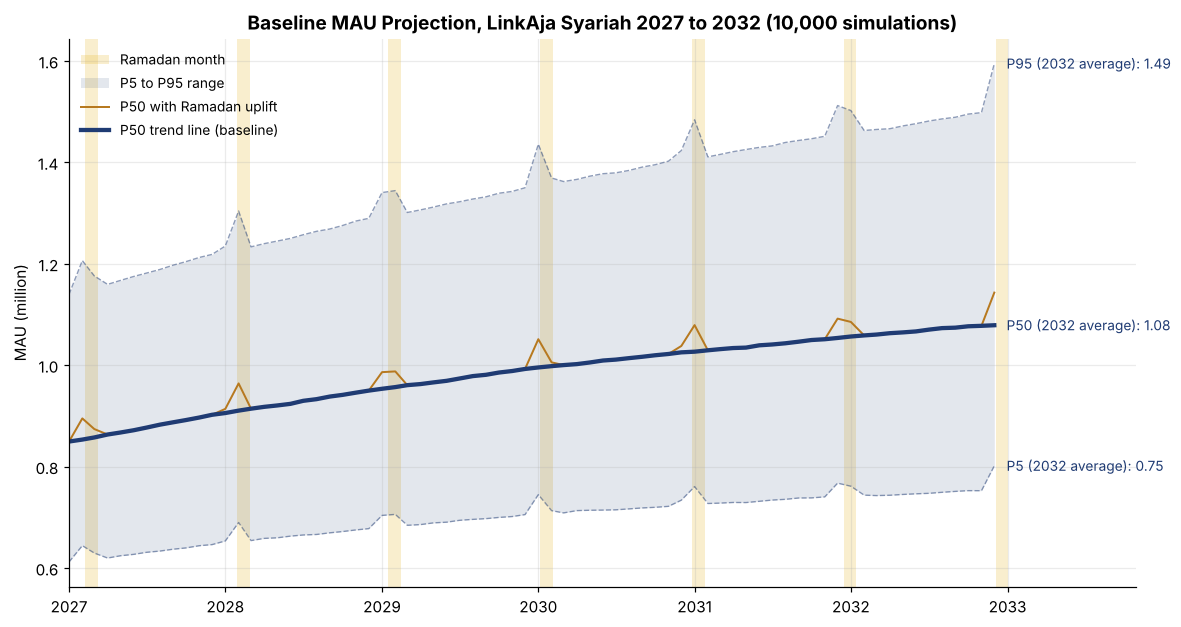

In [16]:
chart_fan(res["MAU"], res["MAU_sa"], np.percentile(target, [5, 50, 95]) / 1e6, f"{OUT}/baseline_MAU_projection.png")

**How to read it.** The middle line (P50) is the baseline: growth keeps flattening at about 4% per year. The P5 to P95 band shows how wide the possibilities are. The absolute MAU level is deliberately not used as a claim, because the starting level of Syariah MAU is not published.

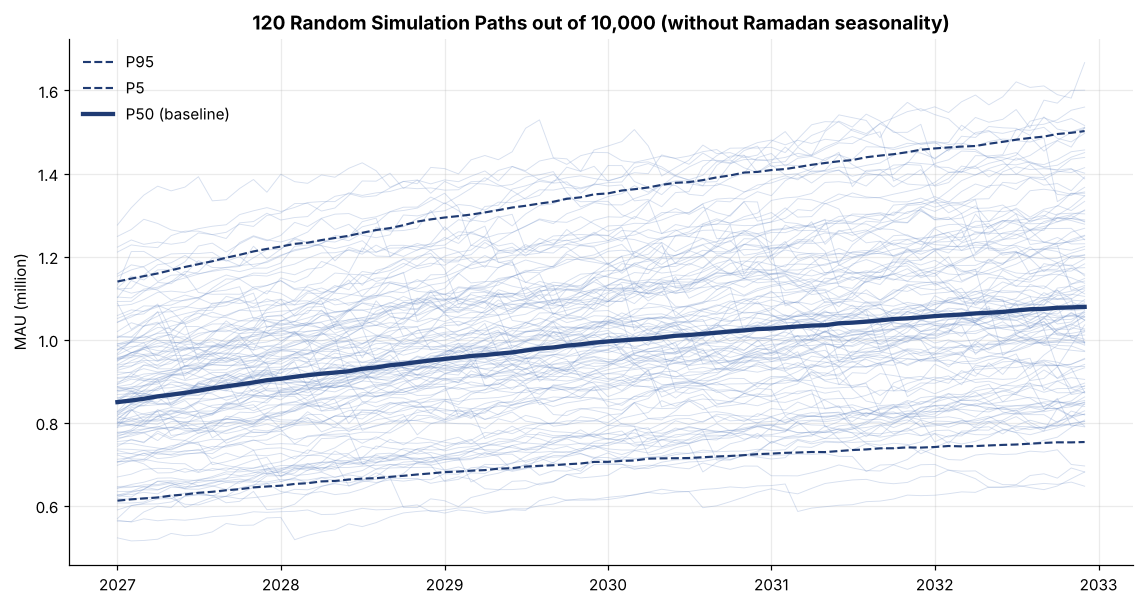

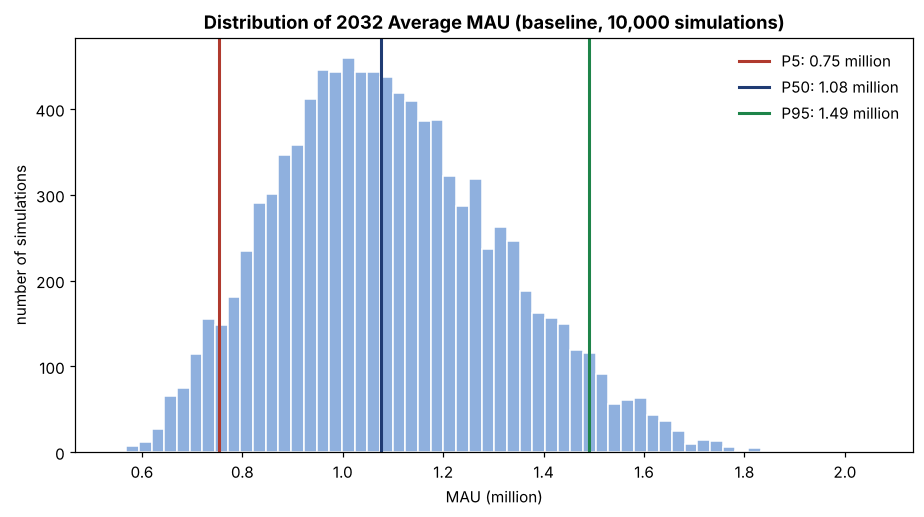

In [17]:
chart_spaghetti(res["MAU_sa"], f"{OUT}/baseline_simulation_paths.png")
chart_hist(target, f"{OUT}/baseline_histogram_MAU_2032.png")

### What makes the result bullish or bearish?

In [18]:
show(tail_table(res["drivers"], mult))

Factor,Bearish (<=P5),All simulations,Bullish (>=P95)
"MAU growth, year 1",0.06,0.09,0.12
"MAU growth, long run",0.02,0.02,0.02
Decay speed of MAU growth,0.50,0.45,0.30
Change in competitive pressure,0.07,0.05,0.01
Number of special events (6 years),2.64,2.00,1.63
Cumulative macro effect,-0.07,-0.01,0.00
MAU sensitivity to consumption,1.55,1.33,1.34
Ramadan amplitude,0.06,0.07,0.07


The table compares the average parameters in the best simulations (bullish, at or above P95 of the 2032 MAU multiple) and the worst ones (bearish, at or below P5). The parameters that differ the most are the main drivers of uncertainty.

# PART 2. How much does MAU rise with the Nava solution?

The solution is applied to the **same baseline paths**. The comparison uses an **index** (MAU in December 2026 = 100 in each simulation) so that the uncertainty about the starting level, which is the same in both worlds, does not blur the effect of the solution. The band is reported as P10 to P90 (80% of simulation results).

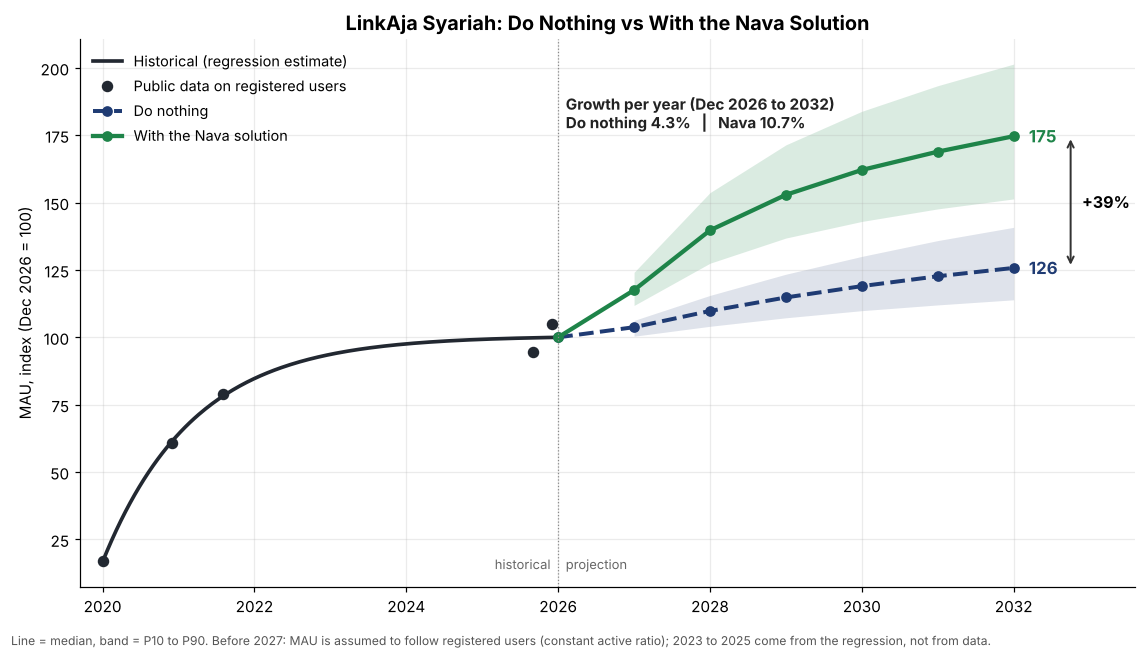

In [19]:
sol = run_solution(res, N)
chart_main(res, sol, f"{OUT}/solution_chart_main.png")

**How to read it.** The green line is the median with the solution, and the dashed blue line is the do-nothing median. On the index, the solution's lower bound (P10) is above the do-nothing upper bound (P90) in every year. Before 2027, the historical line is a saturating exponential regression on five public data points of registered users (constant active ratio), so 2023 to 2025 are estimates, not data.

In [20]:
print("Indexed MAU (Dec 2026 = 100)")
show(table_index(res, sol), 1)
print("Yearly average MAU (million)")
show(table_main(res, sol))

Indexed MAU (Dec 2026 = 100)


Year,Do nothing P10,Do nothing P50,Do nothing P90,Solution P10,Solution P50,Solution P90,Solution P10 above do nothing P90,Solution wins in the same simulation (%)
2027,100.4,103.8,106.3,111.8,117.5,124.1,True,100.0
2028,104.1,109.8,115.6,127.5,139.7,153.7,True,100.0
2029,107.3,114.8,123.4,136.9,152.9,171.4,True,100.0
2030,109.9,119.0,130.0,143.0,162.1,183.9,True,100.0
2031,112.0,122.7,135.9,147.7,168.9,193.4,True,100.0
2032,113.9,125.8,140.8,151.4,174.7,201.4,True,100.0


Yearly average MAU (million)


Year,Do nothing P10,Do nothing P50,Do nothing P90,Solution P10,Solution P50,Solution P90
2027,0.68,0.88,1.12,0.78,1.00,1.28
2028,0.72,0.93,1.19,0.92,1.21,1.47
2029,0.75,0.98,1.25,1.02,1.34,1.57
2030,0.78,1.02,1.31,1.08,1.43,1.64
2031,0.80,1.05,1.36,1.13,1.50,1.70
2032,0.82,1.08,1.40,1.18,1.55,1.74


In [21]:
print("MAU uplift over do nothing in the same simulation (%)")
show(table_uplift_by_year(res, sol), 1)

MAU uplift over do nothing in the same simulation (%)


Year,Uplift P10 (%),Uplift P50 (%),Uplift P90 (%)
2027,9.0,13.3,19.1
2028,17.8,27.2,38.7
2029,20.4,33.4,47.3
2030,20.6,36.4,51.7
2031,20.1,38.1,54.4
2032,19.1,39.4,56.3


In [22]:
show(table_summary(res, sol))

Measure,Value
MAU uplift 2032 P10 (%),19.13
MAU uplift 2032 P50 (%),39.38
MAU uplift 2032 P90 (%),56.33
"MAU 2032 do nothing, P50 (million)",1.08
"MAU 2032 with solution, P50 (million)",1.55
"Extra MAU 2032, paired median (million)",0.40
"MAU growth per year, do nothing, P50 (%)",4.39
"MAU growth per year, with solution, P50 (%)",10.77
"MAU growth in year 1, with solution, P50 (%)",18.15
"Registered-user uplift 2032, P50 (%)",10.47


**How to read it.** "Uplift" and "extra MAU" are computed as the median of the per-simulation difference (paired), so they are free of random luck. In absolute levels, the do-nothing and solution bands still overlap a little because the starting MAU level is unknown. That is why the main comparison uses the index and paired simulations.

### Random paths: do nothing vs with solution

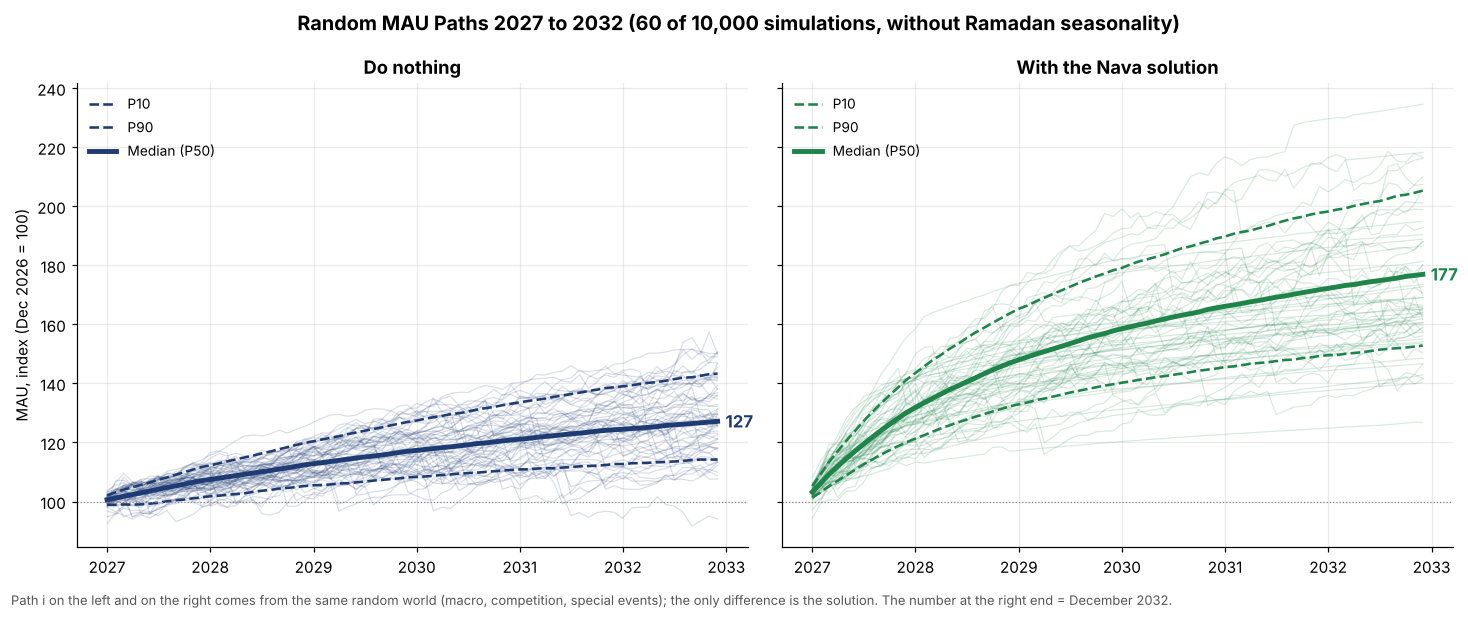

In [23]:
chart_paths(res, sol, f"{OUT}/solution_random_paths.png")

The same sixty random worlds are drawn twice. World i on the left and on the right shares the same macro conditions and shocks, so the only difference is the solution.

### Distribution of 2032 results

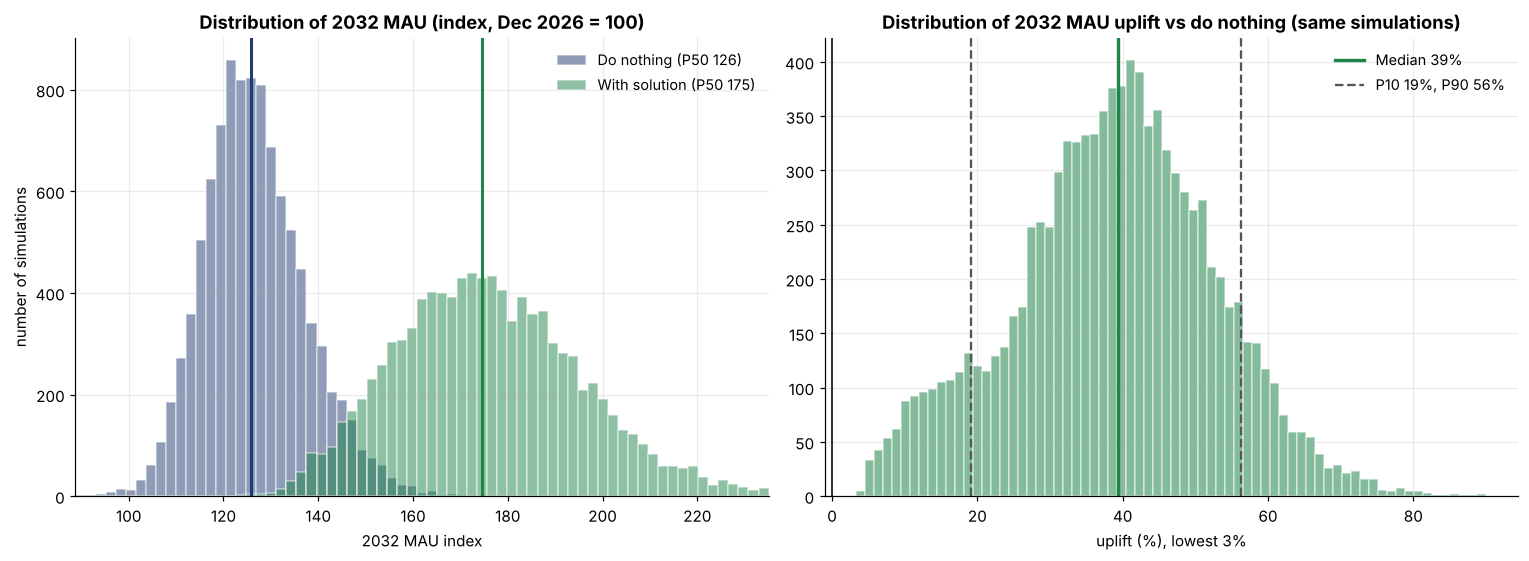

In [24]:
chart_distribution(res, sol, f"{OUT}/solution_distribution_2032.png")

The left histogram shows the distribution of the indexed 2032 MAU in both worlds. The right histogram shows the distribution of the uplift in the same simulations: every simulation is positive because the pillar effects in the model are positive, but the size varies a lot.

# PART 3. Which pillar does the work?

Each pillar is run alone in the same worlds and then compared with the combination of all three. The single-pillar effects add up to a little more than the combined effect because of overlap and the active-ratio cap.

Pillar,MAU uplift 2032 P50 (%),P10 (%),P90 (%)
Pillar 1 (Nava app),19.50,7.51,31.85
Pillar 2 (activation),7.86,4.58,12.28
Pillar 3 (loyalty),14.66,6.88,21.42
Combined (after overlap),39.38,19.13,56.33


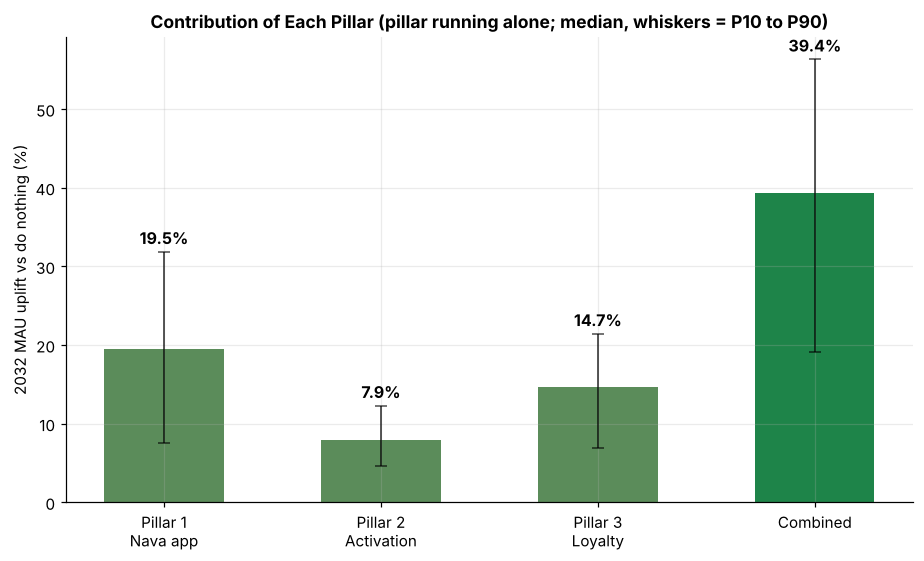

In [25]:
show(table_pillars(res, sol))
chart_pillars(res, sol, f"{OUT}/solution_pillar_contribution.png")

**How to read it.** Pillar 1 (the app) contributes the most because it shifts the active ratio for the entire user base. Pillar 2 only adds new users. Pillar 3 raises retention, and its effect grows because retention compounds.

### Which assumptions matter most? (Spearman rank correlation with the 2032 MAU uplift)

In [26]:
show(table_sensitivity(res, sol))

parameter,spearman
m1,0.39
u2,0.24
om,0.22
g3,0.17
m3,0.16
q,0.06
t3,-0.03
t1,-0.02
t2,0.00


The parameters at the top of the table are the assumptions most worth validating with client data. The build-up times (t1, t2, t3) hardly change the 2032 result, but they change how fast the impact becomes visible.

# PART 4. Yearly growth and cost break-even

The "+39% uplift" is a difference against do nothing, not the growth of Nava itself. Nava's growth against today's level is larger, and it is reported here as the CAGR (compound annual growth rate).

In [27]:
c = table_cagr(res, sol)
show(pd.DataFrame({
    "Condition": c["Condition"],
    "CAGR Dec 2026 to 2032, P10 (%/yr)": c.iloc[:, 1], "P50": c.iloc[:, 2], "P90": c.iloc[:, 3],
    "Total growth 2032 vs Dec 2026, P50 (%)": c.iloc[:, 8]}))

Condition,"CAGR Dec 2026 to 2032, P10 (%/yr)",P50,P90,"Total growth 2032 vs Dec 2026, P50 (%)"
Do nothing,2.40,4.26,6.42,25.77
With the Nava solution,7.83,10.67,13.58,74.66


Growth of each year over the previous year (2027 is compared with December 2026 MAU):

In [28]:
show(table_yearly_growth(res, sol))

Year,Do nothing P50 (%),With Nava P50 (%),With Nava P10 (%),With Nava P90 (%)
2027,3.76,17.54,11.83,24.13
2028,6.12,19.07,12.07,25.57
2029,4.88,9.52,4.57,14.41
2030,3.94,5.63,2.54,10.14
2031,3.31,3.79,1.57,8.03
2032,2.83,2.94,0.96,6.84


**How to read it.** Nava's growth is largest in 2027 to 2028, while pillars 1 and 2 build up, and then it flattens. Compounding retention (G3) keeps Nava above do nothing in 2030 to 2031, but by 2032 the gap has almost disappeared. The reason: the effects of pillars 1 and 2 are one-off jumps in level, and the 12.5% active-ratio cap already holds the result back in about half of the simulations in 2032. That cap comes from a single comparator (Muslim Pro), so loosening it is a team decision, not a result from data.

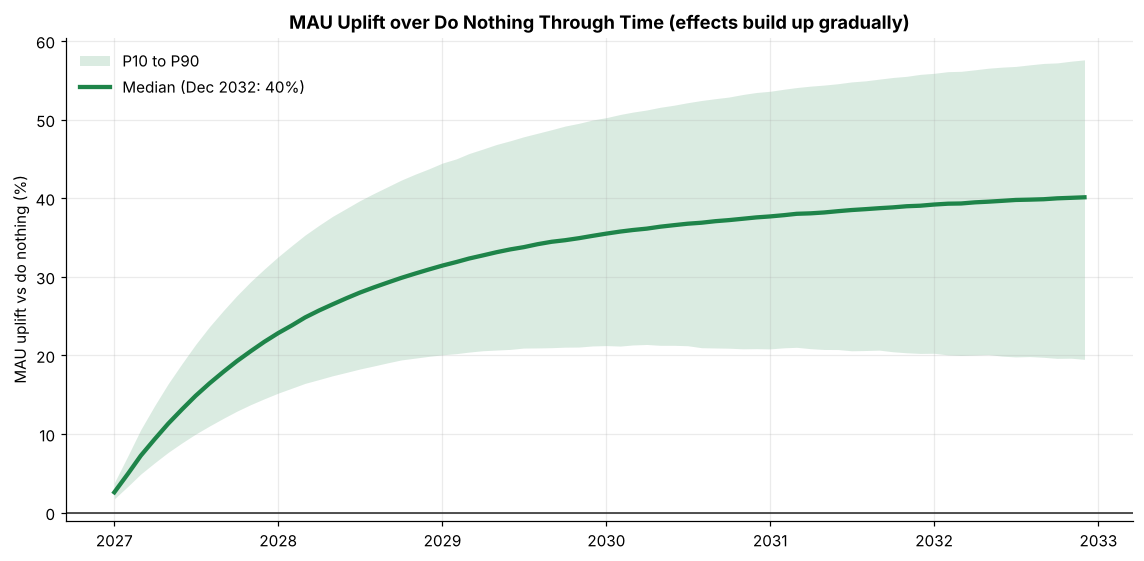

In [29]:
chart_uplift(res, sol, f"{OUT}/solution_uplift_over_time.png")

### Cost break-even

The question "is the cost worth it" is answered with break-even, not with a percentage uplift. The table shows the minimum net revenue per extra MAU per year needed to cover the cost. **The costs below are illustrative, not the proposal's costs.** The absolute MAU level depends on the assumed starting MAU, so this calculation must be redone with the client's numbers.

In [30]:
show(table_breakeven(res, sol))

"Total cost 2027 to 2032 (IDR billion, illustrative)",Extra user-years P10 / P50 / P90 (million),"Minimum net revenue per extra MAU per year, at P90 (IDR thousand)","Minimum net revenue per extra MAU per year, at P50 (IDR thousand)","Minimum net revenue per extra MAU per year, at P10 (IDR thousand)"
10,1.20 / 1.84 / 2.54,3.94,5.45,8.33
25,1.20 / 1.84 / 2.54,9.86,13.62,20.82
50,1.20 / 1.84 / 2.54,19.72,27.25,41.64
100,1.20 / 1.84 / 2.54,39.44,54.49,83.28


### Do the seemingly conservative assumptions hold the result back?

Each row changes **one** assumption and keeps the rest fixed. None of the three loosenings has supporting data yet, so the reference values stay. The table shows how much room there would be if LinkAja provides data that supports them.

In [31]:
a = table_assumption_audit(res)
a.columns = ["Assumption variation", "Uplift P10 (%)", "Uplift P50 (%)", "Uplift P90 (%)", "Solution CAGR P50 (%/yr)"]
show(a, 1)

Assumption variation,Uplift P10 (%),Uplift P50 (%),Uplift P90 (%),Solution CAGR P50 (%/yr)
Model as used (reference),19.9,39.6,56.6,10.7
Active-ratio cap 15% (reference 12.5%),30.5,44.0,60.2,11.5
No active-ratio cap (only the 35% cap of the baseline model),31.9,45.5,62.3,11.7
No pillar-overlap discount (omega = 1),20.0,44.8,63.8,11.4
"Cross-sell from the LinkAja base, U1 = 0 / 2% / 5% (reference 0)",22.3,41.7,59.0,11.0
All three at once,41.0,56.5,74.7,13.2


# PART 5. Probability that the solution succeeds

The results above answer "how large is the impact if the pillars run as designed". A different question is: **what is the probability that this solution actually succeeds**, if a pillar can fail completely (for example the app gets few downloads, or a campaign produces no sign-ups)?

**Method.** In each simulation, each pillar fails completely with an initial probability *f*. Pillar 3 only runs if the app (pillar 1) runs. The size of the pillar effects is not changed to reach a given number. The value of *f* is an assumption because there is no failure data for LinkAja pillars. As a rough reference, the product-launch literature puts failure at about 25% to 45% (secondary sources, consumer products, not financial apps), so the headline uses **f = 30%** and the range 0% to 40% is shown.

**Mitigation design** (valid only if it really is in the proposal's implementation plan):
- **Pillar 1, staged pilot.** If the first launch fails, the app is fixed and relaunched once. The relaunch fails again with probability 50%, and the effects are delayed by 9 months.
- **Pillars 2 and 3, parallel channels.** Activation uses three groups of channels and loyalty uses three features. A pillar fails only if all three fail, plus a 10% probability that all fail from a common cause.

The three mitigation numbers (10%, 50%, 9 months) are team assumptions.

**Definitions of success** (all reported so the result does not depend on one threshold): above do nothing; a 2032 MAU uplift of at least 10%, 20%, or 30%; and a 2032 MAU above the do-nothing P90.

In [32]:
tp = table_success(res, sol)
tp.columns = ["Design", "Initial failure f (%)", "Above do nothing", "Uplift >= 10%", "Uplift >= 20%",
              "Uplift >= 30%", "Above do-nothing P90", "Median uplift (%)", "Target at 80% confidence (%)"]
show(tp[tp["Design"] == "Without mitigation"], 1)
show(tp[(tp["Design"] == "With mitigation") & (tp["Initial failure f (%)"] > 0)], 1)

Design,Initial failure f (%),Above do nothing,Uplift >= 10%,Uplift >= 20%,Uplift >= 30%,Above do-nothing P90,Median uplift (%),Target at 80% confidence (%)
Without mitigation,0.0,100.0,97.7,89.2,75.1,69.7,39.4,27.6
Without mitigation,10.0,98.7,89.1,77.5,61.0,61.2,34.8,18.1
Without mitigation,20.0,95.5,80.6,66.3,49.0,53.7,29.5,10.2
Without mitigation,30.0,90.2,71.7,55.8,38.5,46.5,24.0,7.2
Without mitigation,40.0,83.1,62.2,45.8,29.2,39.8,16.8,4.3


Design,Initial failure f (%),Above do nothing,Uplift >= 10%,Uplift >= 20%,Uplift >= 30%,Above do-nothing P90,Median uplift (%),Target at 80% confidence (%)
With mitigation,10.0,99.3,93.1,81.9,64.6,63.7,35.9,21.4
With mitigation,20.0,98.6,89.4,77.7,61.1,61.2,34.7,18.3
With mitigation,30.0,97.8,85.9,73.3,57.0,58.3,33.1,14.1
With mitigation,40.0,96.6,81.4,67.7,51.5,54.5,30.8,10.7


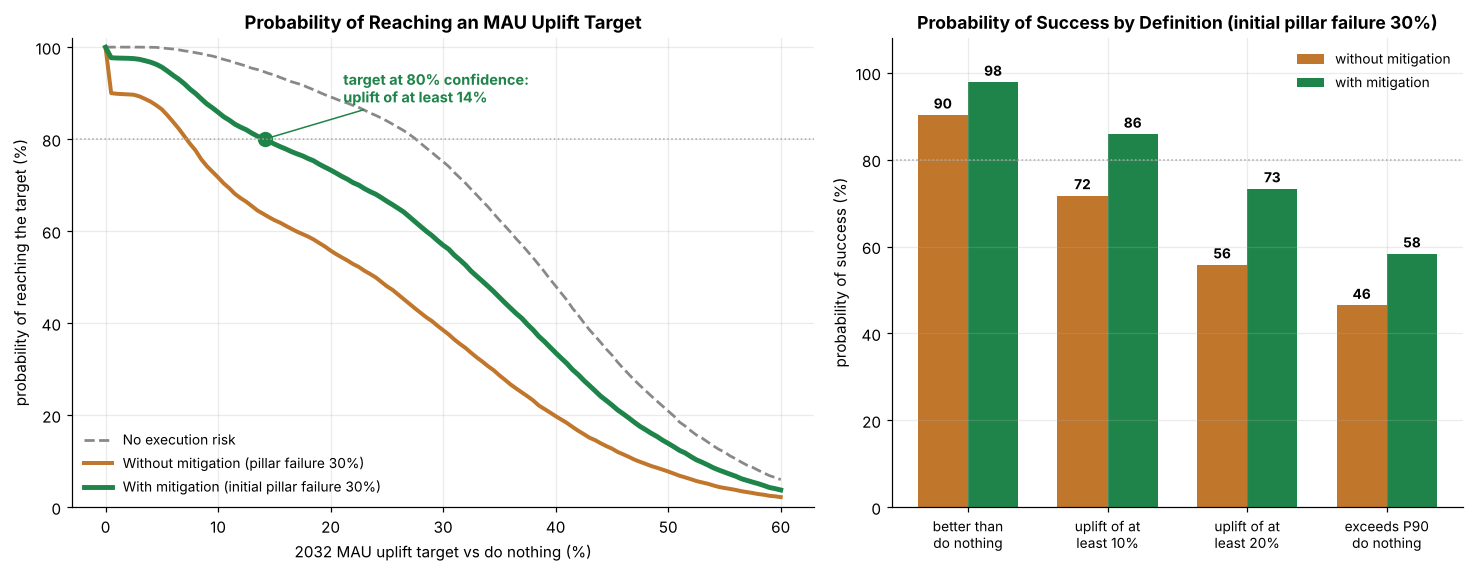

In [33]:
chart_success(res, sol, f"{OUT}/solution_probability_of_success.png")

**How to read it.**
- Left chart: for each uplift target (x axis), the probability that the solution reaches it (y axis). The green dot is the **target that can be promised with 80% confidence**.
- Right chart: the probability of success under four definitions, without and with mitigation, at f = 30%.
- A probability above 80% is reached under the looser definitions (better than do nothing, uplift of at least 10%). Under the stricter definitions (at least 20%, or above the do-nothing P90) the probability is lower, and it is not raised by changing the pillar effects.
- The usual way to state a target is the value exceeded with a given probability, not the middle value.

### Which pillars run in each condition? (initial failure f = 30%)

In [34]:
print("Without mitigation")
show(table_conditions(res, sol, mitigation=False))
print("With mitigation")
show(table_conditions(res, sol, mitigation=True))

Without mitigation


Pillars running,Probability of condition (%),Median MAU uplift (%),Probability of exceeding do nothing P90 (%)
Pillar 1 + Pillar 2 + Pillar 3,34.76,38.97,69.02
Pillar 2,20.63,7.85,18.52
Pillar 1 + Pillar 2,15.03,26.08,47.24
Pillar 1 + Pillar 3,14.23,29.27,55.80
No pillar runs,9.15,0.00,10.16
Pillar 1,6.20,19.47,43.23


With mitigation


Pillars running,Probability of condition (%),Median MAU uplift (%),Probability of exceeding do nothing P90 (%)
Pillar 1 + Pillar 2 + Pillar 3,66.37,39.13,68.62
Pillar 2,12.31,7.92,18.36
Pillar 1 + Pillar 2,9.16,25.84,49.67
Pillar 1 + Pillar 3,8.91,29.03,57.80
No pillar runs,1.97,0.00,11.68
Pillar 1,1.28,20.29,45.31


**Limitation of the method.** Failure is binary and mostly independent. In reality pillars can fail partially and be correlated (same budget and team), so real results will be more volatile than this model.

## Headline numbers for the proposal

In [35]:
yb = yearly(res["MAU_sa"])[0]; ys = yearly(sol["mau_sa"])[0]; m0 = res["MAU0"]
cg_b = ((yb[:, -1] / m0) ** (1 / EFFECTIVE_YEARS) - 1) * 100
cg_s = ((ys[:, -1] / m0) ** (1 / EFFECTIVE_YEARS) - 1) * 100
up = (yearly(sol["mau"])[0][:, -1] / yearly(res["MAU"])[0][:, -1] - 1) * 100
q = lambda x: np.percentile(x, [10, 50, 90])
tp2 = table_success(res, sol)
mit = tp2[(tp2["Design"] == "With mitigation") & (tp2["Initial pillar failure probability (%)"] == 30)].iloc[0]
print(f"2032 MAU uplift vs do nothing        : P50 {q(up)[1]:.0f}%  (P10 {q(up)[0]:.0f}%, P90 {q(up)[2]:.0f}%)")
print(f"MAU growth per year                  : do nothing {np.median(cg_b):.1f}%  vs  Nava {np.median(cg_s):.1f}%")
print(f"Total growth 2032 vs Dec 2026        : do nothing +{np.median(yb[:, -1] / m0 - 1) * 100:.0f}%  vs  Nava +{np.median(ys[:, -1] / m0 - 1) * 100:.0f}%")
print(f"Solution wins in the same simulation : {np.mean(ys[:, -1] > yb[:, -1]) * 100:.0f}%")
print(f"With mitigation, initial failure 30% : above do nothing {mit.iloc[2]:.0f}%, uplift >= 10% {mit.iloc[3]:.0f}%, "
      f"uplift >= 20% {mit.iloc[4]:.0f}%")
print(f"Target at 80% confidence             : MAU uplift of at least {mit.iloc[8]:.0f}% in 2032")

2032 MAU uplift vs do nothing        : P50 39%  (P10 19%, P90 56%)
MAU growth per year                  : do nothing 4.3%  vs  Nava 10.7%
Total growth 2032 vs Dec 2026        : do nothing +26%  vs  Nava +75%
Solution wins in the same simulation : 100%
With mitigation, initial failure 30% : above do nothing 98%, uplift >= 10% 86%, uplift >= 20% 73%
Target at 80% confidence             : MAU uplift of at least 14% in 2032
